# Redder-wavelength fiducial configs: SIFS 700R and Goodman red, with a real spectrum

**Why this notebook exists.** Both `kino/config/sifs.yaml` (700M grating) and `kino/config/goodman.yaml`
(930 l/mm, EG 21-derived throughput) have *measured* system throughput only up to ~730-685 nm. A
real Halpha target at $z\gtrsim0.11$-$0.13$ needs wavelength coverage beyond that -- and neither
instrument has a published or measured efficiency curve there yet (checked 2026-10-09; see the new
configs' own headers). `kino/config/sifs_700r.yaml` and `kino/config/goodman_red.yaml` extend each
instrument's real measured curve with a clearly-labelled **fiducial** continuation (flat at the last
measured value -- a conservative, not optimistic, choice) so a target at these redshifts can still be
forecast. This notebook exercises both configs against a real archival spectrum, as a sanity check
before using them for anything that matters.

> **This spectrum was found by a blind SDSS query** (redshift + S/N cuts only), unrelated to any
> candidate-target list -- its position is openly reported below, same as notebook 11's target.

In [1]:
import time

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
from astropy.coordinates import SkyCoord
from kino_style import BLUE, ORANGE

from kino.analysis.forecast import ForecastTarget, forecast_ifu, forecast_slit
from kino.galaxy import DiscGalaxy
from kino.instruments.ifu import IFU
from kino.instruments.slit import SlitSpectrograph
from kino.io.spectrum import measure_line_flux, read_spectrum
from kino.observing import SOAR, SkyLibrary, night_window, solar_flux

lib = SkyLibrary.load("../data/skycalc")
sifs_r = IFU.from_config("../kino/config/sifs_700r.yaml")
goodman_r = SlitSpectrograph.from_config("../kino/config/goodman_red.yaml")
night = night_window(SOAR, "2026-09-15")
F107 = solar_flux("2026-09")[0]
print(f"night {night.start.iso[:16]} -> {night.end.iso[:16]} UT ({night.duration:.1f})")
print(f"F10.7 = {F107:.0f} s.f.u. (NOAA predicted)")

night 2026-09-15 23:57 -> 2026-09-16 09:17 UT (9.3 h)
F10.7 = 130 s.f.u. (NOAA predicted)


## 1. A real spectrum at z ~ 0.15

Found via a blind SDSS DR17 SkyServer SQL query (`SpecObj` joined to `galSpecLine`, strong-Hα,
$z$ between 0.13 and 0.17, southern declination) -- the same method as notebook 11, just at a
higher redshift so Halpha falls past both instruments' measured coverage.

wavelength range: 3826 Angstrom -- 9215 Angstrom
KINO-measured F(Halpha)  = 1.448e-14 erg / (s cm2) +/- 8.8e-17 erg / (s cm2)  (S/N 165)
MPA-JHU catalog F(Halpha) = 1.144e-14 erg / (s cm2)
agreement: +26.5%
  (likely some [NII] 6548/6584 blending at this resolution/S/N --
  measure_line_flux fits a single Gaussian, no deblending)
observed Halpha wavelength: 755.9 nm
  (needs the fiducial, not measured, red throughput extension)



Hopkins+2003 aperture correction: 1.46x
whole-galaxy F(Halpha) = 2.114e-14 erg / (s cm2)


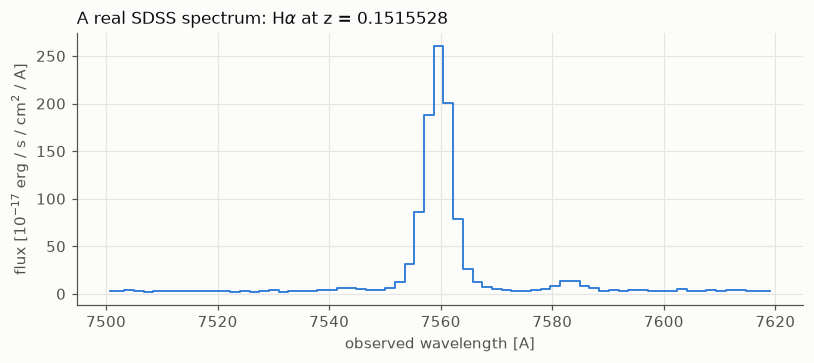

In [2]:
Z = 0.1515528
flam17 = 1e-17 * u.erg / u.s / u.cm**2 / u.AA
spec = read_spectrum("data/sdss_redder_demo.fits", hdu=1, flux_unit=flam17)
m = measure_line_flux(spec, Z, "Halpha")
CATALOG_FLUX = 1144.109e-17 * u.erg / u.s / u.cm**2  # MPA-JHU galSpecLine h_alpha_flux
print(f"wavelength range: {spec.wavelength.min():.0f} -- {spec.wavelength.max():.0f}")
print(f"KINO-measured F(Halpha)  = {m.flux:.3e} +/- {m.flux_err:.1e}  (S/N {m.snr:.0f})")
print(f"MPA-JHU catalog F(Halpha) = {CATALOG_FLUX:.3e}")
print(f"agreement: {(m.flux / CATALOG_FLUX - 1) * 100:+.1f}%")
print("  (likely some [NII] 6548/6584 blending at this resolution/S/N --")
print("  measure_line_flux fits a single Gaussian, no deblending)")
obs_nm = 656.461 * (1 + Z)
print(f"observed Halpha wavelength: {obs_nm:.1f} nm")
print("  (needs the fiducial, not measured, red throughput extension)")

sel = (spec.wavelength.value > obs_nm * 10 - 60) & (spec.wavelength.value < obs_nm * 10 + 60)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.step(spec.wavelength.value[sel], spec.flux.value[sel], where="mid", color=BLUE, lw=1.2)
ax.set_xlabel("observed wavelength [A]")
ax.set_ylabel("flux [$10^{-17}$ erg / s / cm$^2$ / A]")
ax.set_title(f"A real SDSS spectrum: H$\\alpha$ at z = {Z}")
fig.tight_layout()

r_petro, r_fiber = 18.9236, 19.33481
APERTURE_CORRECTION = 10 ** (-0.4 * (r_petro - r_fiber))
WHOLE_GALAXY_FLUX = m.flux * APERTURE_CORRECTION
print(f"\nHopkins+2003 aperture correction: {APERTURE_CORRECTION:.2f}x")
print(f"whole-galaxy F(Halpha) = {WHOLE_GALAXY_FLUX:.3e}")

## 2. The target and the forecast

A modest, compact disc ($r_e$ close to the photometric $r_{50}=0.87''$), through both redder-config
variants at the same seeing/time grid, same 1-hour exposure budget.

both forecasts: 134 s
  seeing  SIFS 700R  Goodman red
     0.6      3.479        0.910
     1.0      2.752        0.802
     1.7      1.941        0.736


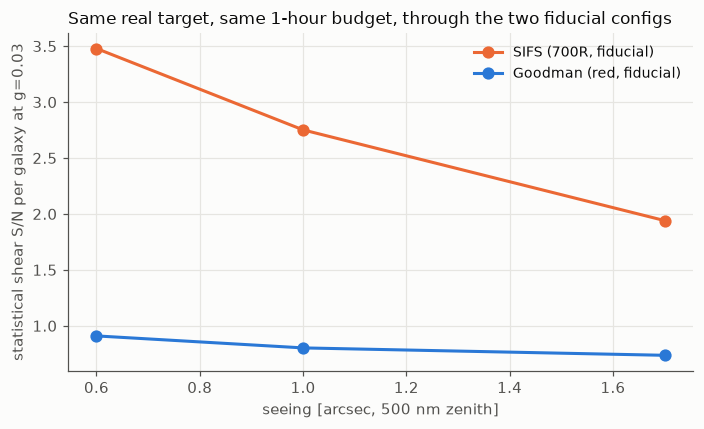

In [3]:
coord = SkyCoord(ra=29.97112 * u.deg, dec=-8.2302741 * u.deg)
gal = DiscGalaxy(r_e=0.87, inc=45.0, pa=20.0, v_flat=170.0, z=Z, sigma0=35.0)
target = ForecastTarget(coord, gal, WHOLE_GALAXY_FLUX, "Halpha", name="SDSS demo (z=0.15)")

SEEING = [0.6, 1.0, 1.7] * u.arcsec
G = 0.03  # a representative shear, just to exercise the pipeline

t0 = time.time()
fc_sifs = forecast_ifu(
    sifs_r, target, night, lib, g=(G, 0.0), seeing_ref=SEEING,
    solar_flux=F107, time_step=240 * u.min,
)  # fmt: skip
fc_goodman = forecast_slit(
    goodman_r, target, night, lib, g=(G, 0.0), seeing_ref=SEEING,
    solar_flux=F107, time_step=240 * u.min,
)  # fmt: skip
print(f"both forecasts: {time.time() - t0:.0f} s")

s_sifs = np.nanmax(fc_sifs.shear_snr_stat, axis=0)
s_goodman = np.nanmax(fc_goodman.shear_snr_stat, axis=0)

fig, ax = plt.subplots(figsize=(6.5, 4.0))
ax.plot(SEEING.value, s_sifs, "o-", color=ORANGE, label="SIFS (700R, fiducial)")
ax.plot(SEEING.value, s_goodman, "o-", color=BLUE, label="Goodman (red, fiducial)")
ax.set_xlabel("seeing [arcsec, 500 nm zenith]")
ax.set_ylabel(f"statistical shear S/N per galaxy at g={G}")
ax.set_title("Same real target, same 1-hour budget, through the two fiducial configs")
ax.legend(fontsize=9)
fig.tight_layout()

print(f"{'seeing':>8s} {'SIFS 700R':>10s} {'Goodman red':>12s}")
for s, sv, gv in zip(SEEING.value, s_sifs, s_goodman, strict=True):
    print(f"{s:8.1f} {sv:10.3f} {gv:12.3f}")

## Caveats

* **The throughput redward of each instrument's measured range is fiducial, not measured** -- see
  `kino/config/sifs_700r.yaml` and `kino/config/goodman_red.yaml`'s own headers for exactly what
  was extrapolated and why. Treat any number here as order-of-magnitude, not a quote.
* **SIFS has no sky background modelled** (a pre-existing placeholder, not new to this notebook) --
  its numbers are optimistic relative to Goodman's, which uses the real sky model.
* **The measured Hα flux likely includes some [NII] 6548/6584 blending** -- `measure_line_flux` fits
  a single Gaussian with no deblending, and this target's SDSS MPA-JHU subclass is `STARBURST`,
  where [NII] can be a significant fraction of the Hα+[NII] blend at this resolution.
* **The target's geometry is illustrative**, not measured for this specific object.